In [1]:
import numpy as np
import matplotlib.pyplot as plt

# list of rules
total_rules = ['111', '110', '101', '100', '011', '010', '001', '000']

In [2]:
# rule translator
def convert_rule_number(number: int):
    str = format(number, f'0{8}b')
    return list(str)
    
# convert_rule_number(150)

def generate_rule_list(rule_number):
    ruled_values = convert_rule_number(rule_number)
    # print(ruled_values)
    assert(len(total_rules) == len(ruled_values))

    # write rules to a dictionary
    rule_dict = {}
    for input, output in zip(total_rules, ruled_values):
        # print(input, output)
        rule_dict[input] = output
    # print(rule_dict)
    return rule_dict

# Rule_dict = generate_rule_list(150)
# print(Rule_dict)

def check_rule_for_position(time, position, matrix):
    out = [0,0,0]
    size = matrix.shape[1]
    out[0] = matrix[time-1, (position-1) % size]
    out[1] = matrix[time-1, position % size]
    out[2] = matrix[time-1, (position+1) % size]
    return f"{out[0]}{out[1]}{out[2]}"

def calculate_value(time, position, matrix, rule_dict):
    rule = check_rule_for_position(time, position, matrix)
    value = int(rule_dict[rule])
    return value

def calculate_value_reverse(time, position, matrix, rule_dict, reverse):
    rule = check_rule_for_position(time, position, matrix)
    value = int(rule_dict[rule])
    if reverse:
        value = (value + matrix[time-2, position]) % 2
    return value



Rules:
{'111': '0', '110': '0', '101': '0', '100': '1', '011': '1', '010': '1', '001': '1', '000': '0'}


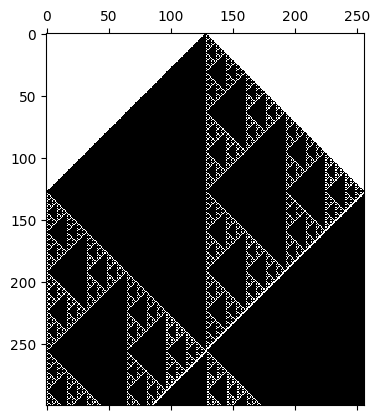

In [3]:
def simulte_cellular_1D(size, start_stop, time_limit, rule_number, reversed=False):
    Matrix = np.zeros((time_limit, size), dtype="int")
    Rule_dict = generate_rule_list(rule_number)
    print(f"Rules:\n{Rule_dict}")
    # first axis is time, second axis is position

    # initialise a state at t = 0
    Matrix[0,start_stop[0]:(start_stop[1]+1)] = 1

    # need to iterate over time
    for time in range(Matrix.shape[0]):
    # for time in [1,2,3,4,5]:
        if time == 0: continue
        # this loop will iterate over all time except 0
        for pos in range(Matrix.shape[1]):
            # compute this for every row
            Matrix[time, pos] = calculate_value_reverse(time, pos, Matrix, Rule_dict, reversed)

    return Matrix

Matrix = simulte_cellular_1D(256, (128,128), 300, 30, True)
plt.matshow(Matrix, cmap="binary")
# cmap binary is 0 = white, 1 = black

In [9]:
# task 2 - microscopic entropy

# generate the list of binary combinations
from itertools import product

def generate_initial_conditions(size):
    binary_combinations = [''.join(bits) for bits in product('01', repeat=size)]
    return binary_combinations

initials = generate_initial_conditions(7)
print(initials)


['0000000', '0000001', '0000010', '0000011', '0000100', '0000101', '0000110', '0000111', '0001000', '0001001', '0001010', '0001011', '0001100', '0001101', '0001110', '0001111', '0010000', '0010001', '0010010', '0010011', '0010100', '0010101', '0010110', '0010111', '0011000', '0011001', '0011010', '0011011', '0011100', '0011101', '0011110', '0011111', '0100000', '0100001', '0100010', '0100011', '0100100', '0100101', '0100110', '0100111', '0101000', '0101001', '0101010', '0101011', '0101100', '0101101', '0101110', '0101111', '0110000', '0110001', '0110010', '0110011', '0110100', '0110101', '0110110', '0110111', '0111000', '0111001', '0111010', '0111011', '0111100', '0111101', '0111110', '0111111', '1000000', '1000001', '1000010', '1000011', '1000100', '1000101', '1000110', '1000111', '1001000', '1001001', '1001010', '1001011', '1001100', '1001101', '1001110', '1001111', '1010000', '1010001', '1010010', '1010011', '1010100', '1010101', '1010110', '1010111', '1011000', '1011001', '1011010'

[0 0 0 0 0 0 0]
[0 0 0 0 0 0 1]
[0 0 0 0 0 1 0]
[0 0 0 0 0 1 1]
[0 0 0 0 1 0 0]
[0 0 0 0 1 0 1]
[0 0 0 0 1 1 0]
[0 0 0 0 1 1 1]
[0 0 0 1 0 0 0]
[0 0 0 1 0 0 1]
[0 0 0 1 0 1 0]
[0 0 0 1 0 1 1]
[0 0 0 1 1 0 0]
[0 0 0 1 1 0 1]
[0 0 0 1 1 1 0]
[0 0 0 1 1 1 1]
[0 0 1 0 0 0 0]
[0 0 1 0 0 0 1]
[0 0 1 0 0 1 0]
[0 0 1 0 0 1 1]
[0 0 1 0 1 0 0]
[0 0 1 0 1 0 1]
[0 0 1 0 1 1 0]
[0 0 1 0 1 1 1]
[0 0 1 1 0 0 0]
[0 0 1 1 0 0 1]
[0 0 1 1 0 1 0]
[0 0 1 1 0 1 1]
[0 0 1 1 1 0 0]
[0 0 1 1 1 0 1]
[0 0 1 1 1 1 0]
[0 0 1 1 1 1 1]
[0 1 0 0 0 0 0]
[0 1 0 0 0 0 1]
[0 1 0 0 0 1 0]
[0 1 0 0 0 1 1]
[0 1 0 0 1 0 0]
[0 1 0 0 1 0 1]
[0 1 0 0 1 1 0]
[0 1 0 0 1 1 1]
[0 1 0 1 0 0 0]
[0 1 0 1 0 0 1]
[0 1 0 1 0 1 0]
[0 1 0 1 0 1 1]
[0 1 0 1 1 0 0]
[0 1 0 1 1 0 1]
[0 1 0 1 1 1 0]
[0 1 0 1 1 1 1]
[0 1 1 0 0 0 0]
[0 1 1 0 0 0 1]
[0 1 1 0 0 1 0]
[0 1 1 0 0 1 1]
[0 1 1 0 1 0 0]
[0 1 1 0 1 0 1]
[0 1 1 0 1 1 0]
[0 1 1 0 1 1 1]
[0 1 1 1 0 0 0]
[0 1 1 1 0 0 1]
[0 1 1 1 0 1 0]
[0 1 1 1 0 1 1]
[0 1 1 1 1 0 0]
[0 1 1 1 1 0 1]
[0 1 1 1

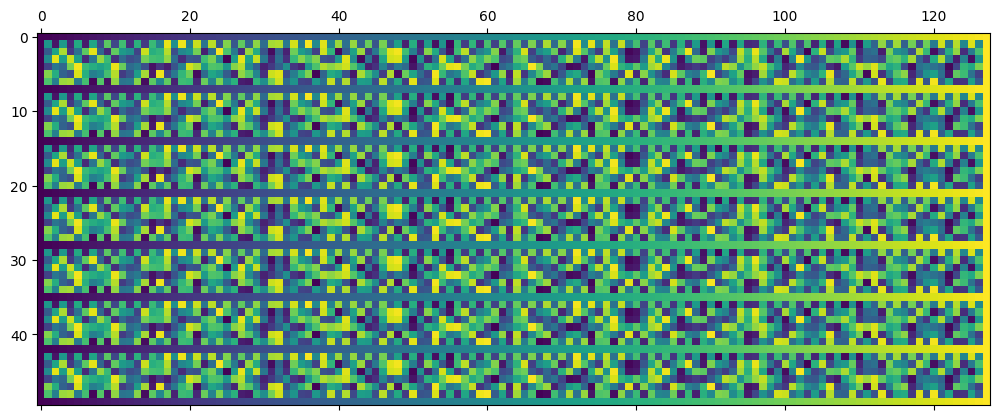

In [17]:
def row_to_decimal(row):
    """Convert a binary row (array of 0/1) to a decimal integer."""
    # row is like [1,0,1,0,1,0,0]
    return int("".join(str(b) for b in row), 2)

def simulte_cellular_1D_initial(initial, time_limit, rule_number, reversed=False):
    size = len(initial)
    row = np.array([int(b) for b in initial])
    print(row)
    Matrix = np.zeros((time_limit, size), dtype="int")
    Rule_dict = generate_rule_list(rule_number)
    # print(f"Rules:\n{Rule_dict}")
    # first axis is time, second axis is position

    # initialise a state at t = 0
    Matrix[0, :] = row

    # need to iterate over time
    for time in range(Matrix.shape[0]):
    # for time in [1,2,3,4,5]:
        if time == 0: continue
        # this loop will iterate over all time except 0
        for pos in range(Matrix.shape[1]):
            # compute this for every row
            Matrix[time, pos] = calculate_value_reverse(time, pos, Matrix, Rule_dict, reversed)

    evolution = np.array([row_to_decimal(row) for row in Matrix])
    return evolution

time_limit = 50
rule_number = 150

# pre-allocate the matrix: shape (time, number of initials)
all_evolutions = np.zeros((time_limit, len(initials)), dtype=int)

for idx, init in enumerate(initials):
    evolution = simulte_cellular_1D_initial(init, time_limit, rule_number)
    all_evolutions[:, idx] = evolution  # assign the evolution column-wise

print(all_evolutions.shape)  # should be (50, len(initials))
plt.matshow(all_evolutions) # time is the y axis, initials is the x axis

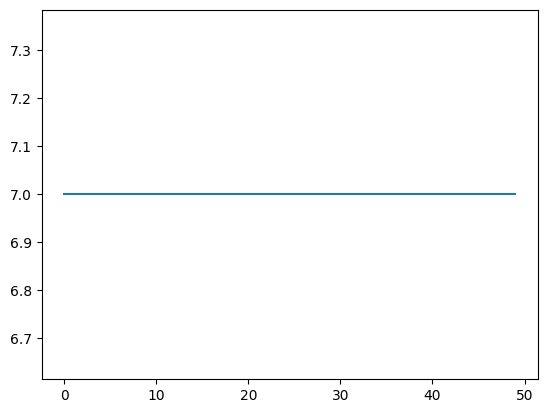

In [16]:
# now calculate the entropy per each row

def row_entropy_Gibbs(row):
    values, counts = np.unique(row, return_counts=True)
    prob = counts / counts.sum()
    S = - np.sum(prob * np.log2(prob))

    return S

entropies = np.array([row_entropy_Gibbs(row) for row in all_evolutions])

plt.plot(entropies)